# ATR-FTIR Kinetics & Equilibrium Analysis of Sulfur Oxyanion Disproportionation

In this assignment, you will analyze ATR-FTIR spectra to study the aqueous disproportionation equilibrium between tetrathionate and sulfite:

**Workflow:**
1. **Part 1 (Reference Analysis & Calibration):** Inspect pure reference spectra, apply local linear baseline subtraction, evaluate Gaussian smoothing vs. peak fitting, and determine a Beer-Lambert calibration factor.
2. **Part 2 (Reaction Progression & Equilibrium):** Track a diagnostic peak across the **start**, **middle**, and **end** of the reaction to quantify concentration changes, average rates, and K

*Note: All helper functions for file I/O and curve fitting are provided below. Fill in the sections marked `# TODO`.*

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit
from scipy.ndimage import gaussian_filter1d
import shutil
import subprocess
from pathlib import Path

# Automatically fetch the 'dataset' folder if running in Google Colab
if not Path("dataset").exists():
    subprocess.run(
        ["git", "clone", "--depth", "1", "https://github.com/annajen225/Spectroscopy-analysis-project.git", "_tmp"],
        check=True,
    )
    Path("_tmp/dataset").rename("dataset")
    shutil.rmtree("_tmp")

DATA_DIR = Path("dataset")
plt.rcParams['figure.figsize'] = (9, 5)
plt.rcParams['font.size'] = 11

def load_spectrum(filepath, wn_min=850, wn_max=1350):
    """
    Loads a 2-column ATR-FTIR CSV (Wavenumber, Absorbance), handles headers/delimiters,
    sorts wavenumbers in ascending order, and slices to [wn_min, wn_max].
    """
    df = pd.read_csv(filepath, sep=None, engine='python', header=None)

    df = df.apply(pd.to_numeric, errors='coerce').dropna()

    wn = df.iloc[:, 0].to_numpy()
    abs_val = df.iloc[:, 1].to_numpy()


    sort_idx = np.argsort(wn)
    wn, abs_val = wn[sort_idx], abs_val[sort_idx]

    mask = (wn >= wn_min) & (wn <= wn_max)
    return wn[mask], abs_val[mask]

def subtract_linear_baseline(wn, abs_val, anchor_low, anchor_high, window=5):
    """
    Subtracts a straight-line baseline anchored by averaging points within
    +/- `window` cm^-1 of `anchor_low` and `anchor_high`.
    """
    y1 = np.mean(abs_val[(wn >= anchor_low - window) & (wn <= anchor_low + window)])
    y2 = np.mean(abs_val[(wn >= anchor_high - window) & (wn <= anchor_high + window)])
    baseline = np.interp(wn, [anchor_low, anchor_high], [y1, y2])
    return abs_val - baseline, baseline

def gaussian(wn, amplitude, center, sigma):
    """Standard Gaussian peak model."""
    return amplitude * np.exp(-0.5 * ((wn - center) / sigma) ** 2)

def fit_gaussian_peak(wn, abs_corr, fit_min, fit_max, center_guess):
    """
    Fits a single Gaussian to `abs_corr` between `fit_min` and `fit_max`.
    Returns: popt (amplitude, center, sigma), integrated_area, fitted_curve_full_wn
    """
    mask = (wn >= fit_min) & (wn <= fit_max)
    wn_sub, y_sub = wn[mask], abs_corr[mask]

    amp_guess = np.max(y_sub)
    sigma_guess = 10.0
    p0 = [amp_guess, center_guess, sigma_guess]
    bounds = ([0, fit_min, 1.0], [np.inf, fit_max, 100.0])
    if not (fit_min <= center_guess <= fit_max):
        raise ValueError(
            f"center_guess ({center_guess}) is outside [fit_min, fit_max] ([{fit_min}, {fit_max}]). "
            "Update center_guess to 940 for sulfite (or 1120 for thiosulfate)."
        )

    amp_guess = max(float(amp_guess), 1e-6)
    sigma_guess = float(np.clip(sigma_guess, 1.01, 99.0)) if np.isfinite(sigma_guess) else 25.0

    p0 = [amp_guess, center_guess, sigma_guess]
    bounds = ([0, fit_min, 1.0], [np.inf, fit_max, 100.0])
    popt, _ = curve_fit(gaussian, wn_sub, y_sub, p0=p0, bounds=bounds)
    popt, _ = curve_fit(gaussian, wn_sub, y_sub, p0=p0, bounds=bounds)
    popt, _ = curve_fit(gaussian, wn_sub, y_sub, p0=p0, bounds=bounds)
    amp, center, sigma = popt
    area = amp * sigma * np.sqrt(2 * np.pi)

    return popt, area, gaussian(wn, *popt)

print("Helper functions loaded successfully.")

Helper functions loaded successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

<>:14: SyntaxWarning: invalid escape sequence '\m'
<>:14: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_616/885236193.py:14: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")


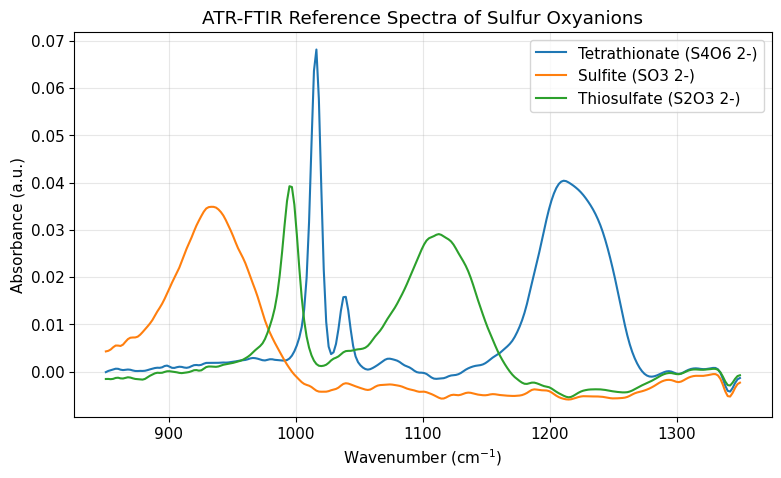

In [7]:
# --- INSTRUCTOR: Update filenames below to match your CSVs ---
ref_files = {
    "Tetrathionate (S4O6 2-)": DATA_DIR / "Tetra_0d25M_airbkg_subH2O.0.csv",
    "Sulfite (SO3 2-)":        DATA_DIR / "Sulfite_0d25M_airbkg_subH2O.0.csv",
    "Thiosulfate (S2O3 2-)":   DATA_DIR / "STS_0d25M_airbkg_subH2O.0.csv",
}

plt.figure()
for label, path in ref_files.items():
    # TODO: Load each spectrum using load_spectrum(path) and plot it
    wn, abs_val = load_spectrum(path)
    plt.plot(wn, abs_val, label=label)

plt.xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")
plt.ylabel("Absorbance (a.u.)")
plt.title("ATR-FTIR Reference Spectra of Sulfur Oxyanions")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:44: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_616/931585879.py:35: SyntaxWarning: invalid escape sequence '\m'
  ax1.set_xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")
/tmp/ipykernel_616/931585879.py:44: SyntaxWarning: invalid escape sequence '\m'
  ax2.set_xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")


Fitted Center: 1116.31 cm^-1 | FWHM: 55.00 cm^-1
Integrated Peak Area: 1.5242 | Calibration Factor: 6.0968 a.u.*cm^-1/M


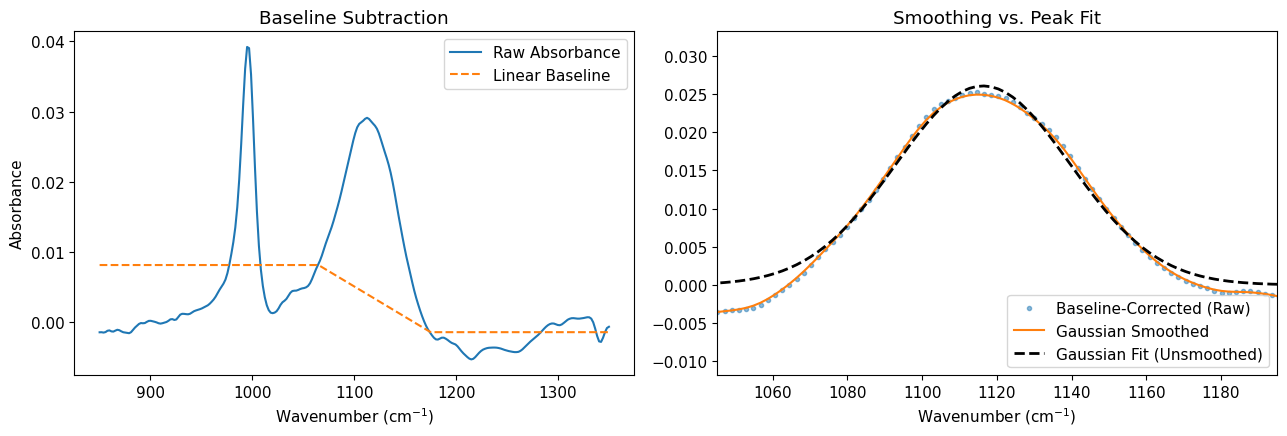

In [5]:
# --- INSTRUCTOR: Set reference concentration (M) and target species ---
C_STD = 0.25  # Molarity of the pure reference standard
target_ref_path = ref_files["Thiosulfate (S2O3 2-)"]  # Update to your chosen peak

wn_ref, abs_ref = load_spectrum(target_ref_path)

# TODO 1: Choose two wavenumber anchor points on flat baseline flanking your diagnostic peak
anchor_low, anchor_high = 1065, 1175
fit_min, fit_max       = 1065, 1175

abs_corr, baseline = subtract_linear_baseline(wn_ref, abs_ref, anchor_low, anchor_high)

# TODO 2: Apply Gaussian smoothing (try sigma = 1, 3, 8) to inspect visual noise vs. distortion
abs_smooth = gaussian_filter1d(abs_corr, sigma=2)

# TODO 3: Fit the UNSMOOTHED baseline-corrected spectrum over the peak window
fit_min = 1065       # Replace with lower bound of peak
fit_max = 1175.0       # Replace with upper bound of peak
center_guess           = 1120.0  # Replace with approximate peak maximum wavenumber

popt, area_ref, fit_curve = fit_gaussian_peak(wn_ref, abs_corr, fit_min, fit_max, center_guess)
amp_ref, center_ref, sigma_ref = popt

# TODO 4: Calculate the Beer-Lambert calibration factor (Area per Molar, or Height per Molar)
cal_factor_area = area_ref / C_STD

print(f"Fitted Center: {center_ref:.2f} cm^-1 | FWHM: {2.355*sigma_ref:.2f} cm^-1")
print(f"Integrated Peak Area: {area_ref:.4f} | Calibration Factor: {cal_factor_area:.4f} a.u.*cm^-1/M")

# Visualization: Raw vs. Smoothed vs. Gaussian Fit
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
ax1.plot(wn_ref, abs_ref, label="Raw Absorbance")
ax1.plot(wn_ref, baseline, "--", label="Linear Baseline")
ax1.set_title("Baseline Subtraction")
ax1.set_xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")
ax1.set_ylabel("Absorbance")
ax1.legend()

ax2.plot(wn_ref, abs_corr, "o", markersize=3, alpha=0.5, label="Baseline-Corrected (Raw)")
ax2.plot(wn_ref, abs_smooth, "-", linewidth=1.5, label="Gaussian Smoothed")
ax2.plot(wn_ref, fit_curve, "k--", linewidth=2, label="Gaussian Fit (Unsmoothed)")
ax2.set_xlim(anchor_low - 20, anchor_high + 20)
ax2.set_title("Smoothing vs. Peak Fit")
ax2.set_xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")
ax2.legend()
plt.tight_layout()
plt.show()

<>:35: SyntaxWarning: invalid escape sequence '\m'
<>:35: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_616/605951202.py:35: SyntaxWarning: invalid escape sequence '\m'
  plt.xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")


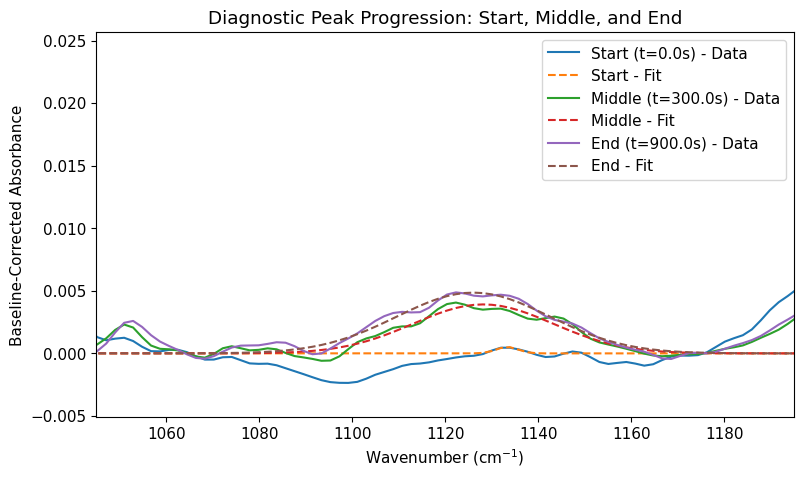

,Stage,Time,Area,Conc_M
0,Start,0.0,0.002994,0.000491
1,Middle,300.0,0.147677,0.024222
2,End,900.0,0.200101,0.032821


Average Rate (Start -> Middle): -7.910e-05 M/s
Equilibrium Concentrations (M): [S4O6]=0.282, [SO3]=0.033, [S2O3]=-0.032, [S3O6]=-0.032
Calculated K_eq = 0.11


In [6]:
# --- INSTRUCTOR: Update file paths, timestamps (in seconds or minutes), and post-mixing [A]_0 ---
kinetics_runs = [
    ("Start",  0.0,   DATA_DIR / "Tetra_20uL_Sulfite_20uL_Rxn2.0000.csv"),
    ("Middle", 300.0, DATA_DIR / "Tetra_20uL_Sulfite_20uL_Rxn2.0016.csv"),
    ("End",    900.0, DATA_DIR / "Tetra_20uL_Sulfite_20uL_Rxn2.0039.csv"),
]

# Initial concentrations AFTER equal-volume mixing (e.g., 0.5 M + 0.5 M -> 0.25 M each)
C_S4O6_init = 0.25  # M
C_SO3_init  = 0.25  # M

results = []
plt.figure()

for stage, t_val, path in kinetics_runs:
    wn, abs_raw = load_spectrum(path)

    # TODO 1: Apply the exact same baseline subtraction and Gaussian fit parameters from Part 1
    anchor_low, anchor_high = 1065, 1175
    fit_min, fit_max       = 1065, 1175
    center_guess           = 1120.0
    abs_corr, _ = subtract_linear_baseline(wn, abs_raw, anchor_low, anchor_high)
    popt, area, fit_curve = fit_gaussian_peak(wn, abs_corr, fit_min, fit_max, center_guess)


    # TODO 2: Convert fitted peak area to concentration using your calibration factor
    conc = area / cal_factor_area

    results.append({"Stage": stage, "Time": t_val, "Area": area, "Conc_M": conc})

    plt.plot(wn, abs_corr, label=f"{stage} (t={t_val}s) - Data")
    plt.plot(wn, fit_curve, "--", label=f"{stage} - Fit")

plt.xlim(anchor_low - 20, anchor_high + 20)
plt.xlabel("Wavenumber ($\mathrm{cm^{-1}}$)")
plt.ylabel("Baseline-Corrected Absorbance")
plt.title("Diagnostic Peak Progression: Start, Middle, and End")
plt.legend()
plt.show()

res_df = pd.DataFrame(results)
display(res_df)

# TODO 3: Stoichiometry & Equilibrium Calculation (S4O6^2- + SO3^2- <-> S2O3^2- + S3O6^2-)
# Assuming the tracked species is a REACTANT (e.g., SO3^2-):
c_start = res_df.loc[0, "Conc_M"]
c_mid   = res_df.loc[1, "Conc_M"]
c_end   = res_df.loc[2, "Conc_M"]

delta_c_total = c_start - c_end  # Extent of reaction (x) at equilibrium
avg_rate_first_half = (c_start - c_mid) / (res_df.loc[1, "Time"] - res_df.loc[0, "Time"])

# Equilibrium concentrations from ICE table (1:1:1:1 stoichiometry):
# (Note: If tracking a PRODUCT instead, x = c_end - c_start)
SO3_eq  = c_end
S4O6_eq = C_S4O6_init - delta_c_total
S2O3_eq = delta_c_total
S3O6_eq = delta_c_total

K_eq = (S2O3_eq * S3O6_eq) / (S4O6_eq * SO3_eq)

print(f"Average Rate (Start -> Middle): {avg_rate_first_half:.3e} M/s")
print(f"Equilibrium Concentrations (M): [S4O6]={S4O6_eq:.3f}, [SO3]={SO3_eq:.3f}, [S2O3]={S2O3_eq:.3f}, [S3O6]={S3O6_eq:.3f}")
print(f"Calculated K_eq = {K_eq:.2f}")

### Post-Analysis Questions (Answer in Markdown Below)

1. **Spectral Preprocessing:** Why do we apply `gaussian_filter1d` only for visual inspection and perform `curve_fit` on the *unsmoothed* data? How does increasing `sigma` in the Gaussian filter bias the extracted peak height and FWHM?
2. **Beer-Lambert Assumptions in Concentrated Solutions:** In ATR-FTIR, the effective penetration depth $d_p$ depends on the refractive index of the solution. How might working at high ionic strength (e.g., molar concentrations) introduce systematic error into a single-point calibration, and why is **integrated peak area** generally more robust than **peak height**?
3. **Kinetics & Equilibrium:** Compare the reaction quotient $Q$ at the **middle** time point to $K_{\text{eq}}$ at the **end**. If you were given 20 evenly spaced spectra instead of 3, how would you linearize the data to extract the forward second-order rate constant $k_f$ (and why would that linear plot curve as $t \to t_{\text{end}}$)?